# Lab 2 | ADF, ARIMA và SARIMA
## Notebook tổng hợp — khung bài thực hành

Phần đầu giới thiệu và trực quan hóa **hai dataset thật** từ liên kết trong đề.
Các phần phân tích phía sau chỉ có tiêu đề, câu hỏi và ô `TODO`, **chưa viết sẵn lời giải**.

**Mục lục**
0. Thiết lập dữ liệu chung
1. Mô tả và xem trước dataset
2. Bài 1 — EDA
3. Bài 2–3 — ADF và sai phân
4. Bài 4 — ACF/PACF
5. Bài 5 — ARIMA, dự báo và đánh giá
6. Nâng cao — SARIMA
7. Kết luận

## 0. Thiết lập dữ liệu chung
Chọn Python 3.12; cài thư viện bằng `python -m pip install -r requirements.txt`.
CSV đã nằm trong repo. Cell dưới chỉ import, đọc dữ liệu và chia train/test theo thời gian.

**Biến dùng chung:** `raw1`, `raw2` là bảng gốc; `y1`, `y2` là chuỗi tháng;
`train1`, `test1`, `train2`, `test2` dùng tỷ lệ 80/20, không shuffle; `SEASON_LENGTH = 12`.
Chỉ chọn phép biến đổi và tham số mô hình từ **train**; test dành cho đánh giá cuối.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display

candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / 'Lab2', Path.cwd() / 'outputs' / 'Lab2']
PROJECT_ROOT = next((p.resolve() for p in candidates if (p / 'src/lab2_data.py').is_file() and (p / 'data/a10.csv').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook from the Lab2 repository.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.lab2_data import load_datasets, chronological_split, TRAIN_RATIO, SEASON_LENGTH

raw1, raw2, y1, y2 = load_datasets()
train1, test1 = chronological_split(y1)
train2, test2 = chronological_split(y2)
shell = get_ipython()
if shell is not None:
    shell.run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Mô tả và xem trước dataset

### Dataset 1 — a10
- Tệp: `data/a10.csv`; cột thời gian `date`, cột giá trị `value`.
- **204 quan sát tháng**, từ **07/1991 đến 06/2008**.
- Chi tiêu trợ giá thuốc chống đái tháo đường A10 tại Australia, đơn vị **triệu đô la**.
- [CSV theo đề](https://raw.githubusercontent.com/selva86/datasets/master/a10.csv) ·
  [Mô tả chính thức của fpp2](https://pkg.robjhyndman.com/fpp2/reference/a10.html).

**Đối chiếu nguồn:** PDF gọi Dataset 1 là “Monthly Retail Sales (US)”, nhưng đường dẫn trong đề trỏ tới `a10.csv`.
Notebook giữ nguyên CSV theo đường dẫn và mô tả đúng bộ dữ liệu a10, không đổi thành dữ liệu bán lẻ.

### Dataset 2 — AirPassengers
- Tệp: `data/airline-passengers.csv`; cột thời gian `Month`, cột giá trị `Passengers`.
- **144 quan sát tháng**, từ **01/1949 đến 12/1960**.
- Tổng hành khách hàng không quốc tế theo tháng, đơn vị **nghìn hành khách**; chu kỳ năm `s = 12`.
- [CSV theo đề](https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv) ·
  [Mô tả chính thức của R](https://stat.ethz.ch/R-manual/R-devel/library/datasets/html/AirPassengers.html).

Các bảng và đồ thị sau là **minh họa trực tiếp dữ liệu gốc**, không phải dữ liệu sinh ngẫu nhiên hay forecast.

In [2]:
dataset_summary = pd.DataFrame([
    {'Dataset': 'a10', 'Số tháng': len(y1), 'Từ': y1.index.min().strftime('%Y-%m'),
     'Đến': y1.index.max().strftime('%Y-%m'), 'Train': len(train1), 'Test': len(test1),
     'Thiếu giá trị': int(y1.isna().sum()), 'Đơn vị': 'Triệu đô la'},
    {'Dataset': 'AirPassengers', 'Số tháng': len(y2), 'Từ': y2.index.min().strftime('%Y-%m'),
     'Đến': y2.index.max().strftime('%Y-%m'), 'Train': len(train2), 'Test': len(test2),
     'Thiếu giá trị': int(y2.isna().sum()), 'Đơn vị': 'Nghìn hành khách'},
])
display(dataset_summary)

,Dataset,Số tháng,Từ,Đến,Train,Test,Thiếu giá trị,Đơn vị
0,a10,204,1991-07,2008-06,163,41,0,Triệu đô la
1,AirPassengers,144,1949-01,1960-12,115,29,0,Nghìn hành khách


### 1.1. Các dòng dữ liệu gốc
Bảng trên: a10. Bảng dưới: AirPassengers. Hiển thị 6 dòng đầu, giữ tên cột gốc.

In [3]:
display(raw1.head(6))
display(raw2.head(6))

,date,value
0,1991-07-01,3.526591
1,1991-08-01,3.180891
2,1991-09-01,3.252221
3,1991-10-01,3.611003
4,1991-11-01,3.565869
5,1991-12-01,4.306371


,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121
5,1949-06,135


### 1.2. Minh họa chuỗi thời gian
Hai đồ thị dùng toàn bộ dữ liệu để xem hình dạng và phạm vi của dataset, chưa phải kết quả mô hình.
Các phân tích chọn tham số bên dưới cần thực hiện trên phần **train** tương ứng.

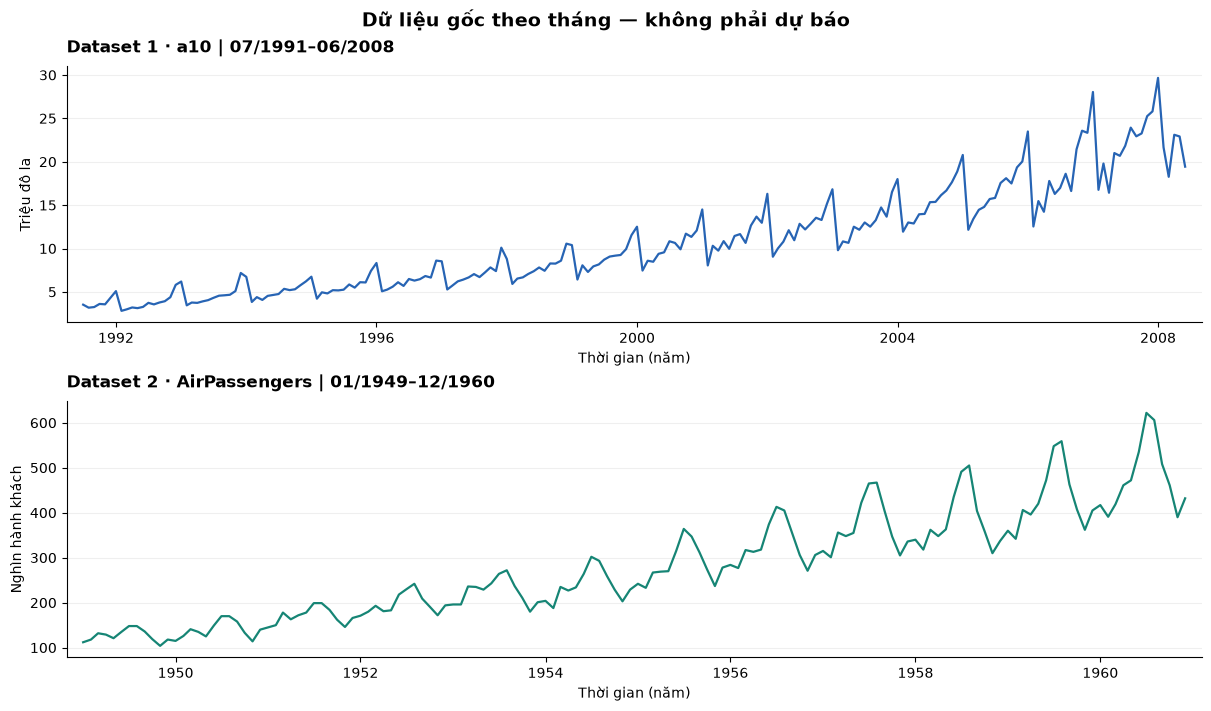

In [4]:
import matplotlib.dates as mdates

fig, axes = plt.subplots(2, 1, figsize=(12, 7), layout='constrained')
for ax, series, title, unit, color in [
    (axes[0], y1, 'Dataset 1 · a10 | 07/1991–06/2008', 'Triệu đô la', '#2764b4'),
    (axes[1], y2, 'Dataset 2 · AirPassengers | 01/1949–12/1960', 'Nghìn hành khách', '#168575'),
]:
    ax.plot(series.index, series.values, color=color, linewidth=1.6)
    ax.set_title(title, loc='left', fontsize=12, fontweight='bold', pad=10)
    ax.set_ylabel(unit)
    ax.set_xlabel('Thời gian (năm)')
    ax.grid(axis='y', alpha=0.2)
    ax.margins(x=0.015)
    locator = mdates.AutoDateLocator(minticks=5, maxticks=8)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.suptitle('Dữ liệu gốc theo tháng — không phải dự báo', fontsize=14, fontweight='bold')
preview_path = PROJECT_ROOT / 'figures/dataset_preview.png'
preview_path.parent.mkdir(exist_ok=True)
fig.savefig(preview_path, dpi=150, bbox_inches='tight')
plt.show()

## 2. Bài 1 — Khám phá dữ liệu (EDA)
Dùng Dataset 1; phần xem trước ở trên chỉ là khởi tạo để quan sát dữ liệu.
### Nhận xét
- Chuỗi có xu hướng không? **TODO**.
- Có dấu hiệu mùa vụ không? **TODO**.
- Chuỗi có khả năng dừng không? **TODO: nhận định sơ bộ, cần kiểm định**.

In [ ]:
# TODO: Bổ sung biểu đồ EDA trên train1 và giải thích bằng chứng cần thiết.

## 3. Bài 2–3 — ADF và sai phân
### 3.1. ADF trên chuỗi gốc
Dùng `train1` chưa sai phân; báo ADF statistic, p-value, mức ý nghĩa và kết luận.
- H₀ của ADF là gì? **TODO**.
- p-value cho biết điều gì? **TODO**.
- Chuỗi có dừng không? **TODO từ kết quả thực chạy**.

In [ ]:
# TODO: Import và thực hiện kiểm định ADF trên train1.
# TODO: Lưu ADF statistic, p-value và các thông tin cần để giải thích.

### 3.2. Sai phân và ADF lần hai
- Đồ thị sau sai phân bậc 1: **TODO**.
- Kết quả kiểm định lại: **TODO**.
- Sau sai phân đã có bằng chứng dừng chưa? **TODO**.
- Giá trị `d` đề xuất và lý do: **TODO**.

In [ ]:
# TODO: Sai phân bậc 1 của train1; xử lý giá trị thiếu do phép sai phân.
# TODO: Vẽ chuỗi sau sai phân và kiểm định lại.
# TODO: Chốt phép xử lý và d từ kết quả; không mặc định chuỗi đã dừng.

## 4. Bài 4 — ACF và PACF
Phân tích chuỗi train đã xử lý phù hợp; không dùng test để đề xuất tham số.
- ACF cắt cụt / suy giảm ở lag nào? **TODO**.
- PACF cắt cụt / suy giảm ở lag nào? **TODO**.
- Đề xuất 1–2 bộ `(p,d,q)` và giải thích: **TODO**.

In [ ]:
# TODO: Nhận phép xử lý/d từ phần ADF, vẽ ACF/PACF trên chuỗi đã xử lý.
# TODO: Đề xuất cấu hình ứng viên và lưu lý do lựa chọn.

## 5. Bài 5 — ARIMA, dự báo và đánh giá
### 5.1. Dữ liệu và thiết lập mô hình
Train/test 80/20 đã chuẩn bị bằng helper chung; giải thích cách chia và vai trò test.
- Vì sao không shuffle dữ liệu chuỗi thời gian? **TODO**.
- Ý nghĩa của `p,d,q` đã chọn: **TODO**.
- AIC/BIC của 1–2 mô hình, mô hình có hội tụ không? **TODO**.
Fit trên `train1` gốc với `d` trong cấu hình; tránh đưa chuỗi đã sai phân vào để sai phân lần nữa.

In [ ]:
# TODO: Fit 1–2 mô hình ARIMA trên train1 theo các cấu hình đã thống nhất.
# TODO: Ghi AIC, BIC, hội tụ và chọn mô hình mà không nhìn test.

### 5.2. Phần dư
- Đồ thị phần dư theo thời gian và ACF phần dư: **TODO**.
- Mean phần dư có gần 0 không? **TODO**.
- Phần dư có phù hợp giả định white noise không? **TODO bằng chứng**.
- Nếu còn tự tương quan, điều chỉnh gì? **TODO**.

In [ ]:
# TODO: Chẩn đoán phần dư và diễn giải kết quả trên mô hình fit từ train1.

### 5.3. Forecast và đánh giá
- Vẽ Train, Test thực tế, Forecast: **TODO**.
- MAE, RMSE, MAPE (%): **TODO**.
- Forecast có bám sát xu hướng không? **TODO**.
- Sai lệch lớn nhất xảy ra ở đâu? **TODO**.
- Chỉ số nào nhạy với outlier nhất? **TODO**.
- RMSE lớn/nhỏ nói lên điều gì trong đơn vị và quy mô dữ liệu? **TODO**.

In [ ]:
# TODO: Forecast đúng len(test1), kiểm tra index khớp với test1.
# TODO: Tính MAE/RMSE/MAPE, vẽ kết quả và tìm thời điểm sai lệch lớn nhất.

## 6. Nâng cao — SARIMA trên Dataset 2
### 6.1. Xử lý và chọn tham số
- Nhận diện mùa vụ: **TODO**.
- ADF chuỗi gốc trên `train2`, sai phân thường/mùa vụ và kiểm định lại: **TODO**.
- ACF/PACF, lựa chọn `p,q,P,Q`: **TODO**.
- Đề cho gợi ý `s=12`, `d=1`, `D=1`; cần kiểm tra và giải thích, không coi là kết quả mặc định.

In [ ]:
# TODO: Dùng train2 để kiểm định, xử lý và phân tích ACF/PACF.
# TODO: Giải thích cấu hình SARIMA được chọn.

### 6.2. Fit, forecast và so sánh
- Fit SARIMA, forecast trên `test2`, đánh giá MAE/RMSE: **TODO**.
- Chạy ARIMA baseline trên **cùng Dataset 2**, cùng train/test và thang đo: **TODO**.
- So sánh forecast, MAE/RMSE; nhận xét ưu/nhược điểm: **TODO**.

In [ ]:
# TODO: Fit ARIMA và SARIMA trên train2 gốc với cấu hình đã chọn.
# TODO: Forecast cùng horizon, kiểm tra index/thang đo rồi so sánh MAE/RMSE.

## 7. Kết luận
- Dataset 1: tính dừng, phép xử lý, cấu hình ARIMA cuối và kết quả đánh giá: **TODO**.
- Dataset 2: cấu hình SARIMA và so sánh với ARIMA: **TODO**.
- Hạn chế và hướng cải thiện: **TODO**.

**Trước khi hoàn tất:** điền hết TODO, kiểm tra số liệu/đồ thị và chạy lại từ kernel mới.
Các bảng và hình xem trước dataset được giữ sẵn; các phần bài làm chưa có lời giải.